### Diabetes Disease Progress Model Deployment

This is a demonstration of deploying the diabetes disease progress linear regression model, trained on the `BMI` feature to predict the `Target`, so a separate Python implementation can use it to make predictions.

This can also be viewed as a Python script in [3.1.1.export_import.py](3.1.1.export_import.py) and [3.1.1.test_import.py](3.1.1.test_import.py).

#### Step 1

Load the required dependencies including [pickle](https://docs.python.org/3/library/pickle.html) the native Python library for serialising data objects:

> [!Caution]
> The pickle module is not secure. Only unpickle data you trust.

In [1]:
# Import frameworks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('../../style_Matplotlib_charts.mplstyle')
from sklearn.linear_model import LinearRegression
import pickle

####  Step 2
- Open and parse the CSV file and store the data as variable array objects.

In [2]:
x_col = 'BMI'
training_data = pd.read_csv('../../2.Model_Development/2.3.Model_Training/2.3.2.training_data.csv')
x = np.array(training_data[x_col]).reshape(-1, 1)
y = np.array(training_data['Target'])

#### Optional Step

Apply your Python skills and query the data set about how many training examples there are and inspect a sample of the data.

In [3]:
m = len(x)
print(f"Number of training examples is: {m}")
table = pd.DataFrame({
    x_col: x.flatten(),  # Flatten x for easy display
    'Target': y
})
print(table.head())

Number of training examples is: 175
    BMI  Target
0  31.9    91.0
1  24.5   148.0
2  30.2    52.0
3  19.6    57.0
4  20.8    72.0




Plot the feature `x` and target `y` data on a graph using the column headings as the graph labels.

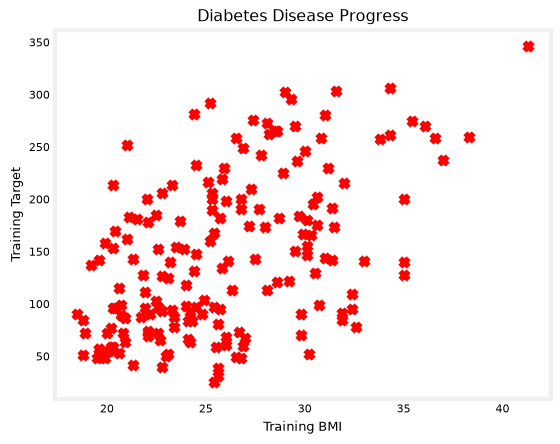

In [4]:
# Plot the data points
plt.scatter(x, y, marker='x', c='r')
# Set the title
plt.title("Diabetes Disease Progress")
# Set the y-axis label
plt.ylabel('Training Target')
# Set the x-axis label
plt.xlabel(f'Training {x_col}')
plt.show()

#### Step 3

Use the [sklearn](https://scikit-learn.org/stable/) library to fit the model to the training data which will provide a line of best fit with the lowest cost based on a [sklearn](https://scikit-learn.org/stable/) algorithm.

In [5]:
# Create the model
my_model = LinearRegression()
# Fit the model to the data
my_model.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[8.28]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-69.33
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[61.21]


#### Step 4

Save the model to file.

In [6]:
# save the model to disk
filename = 'my_saved_model.sav'
pickle.dump(my_model, open(filename, 'wb'))

#### Step 5
In a separate Python implementation import the file and make a prediction.

In [7]:
filename = 'my_saved_model.sav'
loaded_model = pickle.load(open(filename, 'rb'))
predict = np.array([30]).reshape(1, -1)
result = loaded_model.predict(predict)
print(result[0])

179.17029388730126



Plot the features, targets and model (linear regression).

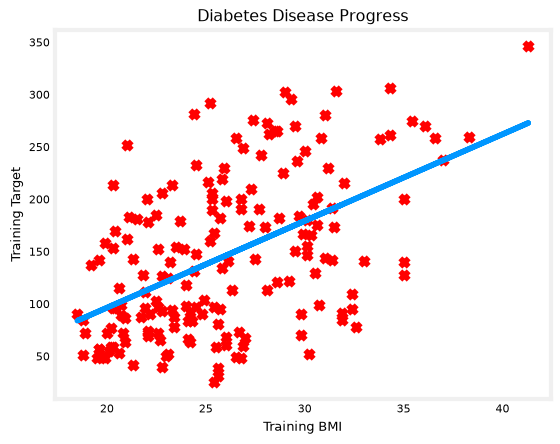

In [8]:
y_pred = my_model.predict(x)
plt.plot(x, y_pred)
plt.scatter(x, y, marker='x', c='r')
plt.title("Diabetes Disease Progress")
plt.ylabel('Training Target')
plt.xlabel(f'Training {x_col}')
plt.show()

Use the model for predictions and plot them on the visualisation that is saved as file `graph.png` for use in a Python Flask UI API endpoint.

In [9]:
predict = np.array([30]).reshape(1, -1)
y_prediction = my_model.predict(predict)

y_pred = my_model.predict(x)
plt.plot(x, y_pred)
plt.scatter(x, y, marker='x', c='r')
plt.scatter(predict, y_prediction, marker='D', c='r', zorder=10, s=100)
plt.text(predict[0,0], y_prediction[0], f"Target {y_prediction[0]:.2f} is prediction from {predict[0,0]} input")
plt.title("Diabetes Disease Progress")
plt.ylabel('Training Target')
plt.xlabel(f'Training {x_col}')
plt.savefig('graph.png')   # save the figure to file
plt.close()    # close the figure window